# Examen de la Unidad 2: raíces de ecuaciones

Métodos cerrados, abiertos, raíces complejas y casos de estudio.
Contesta en orden; la calificación es automática.

In [1]:
#@title ⚙️ Configuración general — ejecuta esta celda PRIMERO (no modificar)
# ============================================================
# Detecta si corre en Colab o en tu computadora y carga el motor del examen.
# ============================================================
import base64
import importlib
import os
import subprocess
import sys
import zlib

import numpy as np
from IPython.display import Markdown, display

try:
    import google.colab
    ES_COLAB = True
except ImportError:
    ES_COLAB = False

REPO_URL = "https://github.com/ITH-MGL-MN/U2_Examen.git"
REPO_NOMBRE = "U2_Examen"

# "modulos" -> profe/** tal cual (para DEPURAR en local).
# "bundle"  -> grader_local.py (el motor aplanado).
# "blob"    -> grader_ofuscado.txt (lo que recibe el alumno en Colab).
MODO_MOTOR = "modulos"

if ES_COLAB:
    BASE = "/content/drive/MyDrive/CursoMN"
    REPO = os.path.join(BASE, REPO_NOMBRE)
else:
    REPO = os.getcwd()
    for _ in range(4):
        if (os.path.exists(os.path.join(REPO, "grader_local.py"))
                or os.path.exists(os.path.join(REPO, "profe"))):
            break
        padre = os.path.dirname(REPO)
        if padre == REPO:
            break
        REPO = padre
    if not (os.path.exists(os.path.join(REPO, "grader_local.py"))
            or os.path.exists(os.path.join(REPO, "profe"))):
        REPO = r"o:\Mi unidad\CursoMN\U2_Examen"

print("Modo          :", "Google Colab" if ES_COLAB else "PC local")
print("Carpeta tarea :", REPO)

if ES_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    os.makedirs(BASE, exist_ok=True)
    if not os.path.exists(REPO):
        subprocess.run(["git", "clone", REPO_URL, REPO], check=True)
    else:
        subprocess.run(["git", "-C", REPO, "pull"])
    print("✅ Repositorio listo en Drive.")
    MODO_MOTOR = "blob"

for pkg in ("sympy", "numpy", "scipy", "matplotlib", "requests", "ipywidgets"):
    try:
        importlib.import_module(pkg)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

sys.path.insert(0, REPO)

if MODO_MOTOR == "modulos":
    from profe.ui.cuaderno import *      # noqa: F401,F403
else:
    if MODO_MOTOR == "blob":
        ruta = os.path.join(REPO, "grader_ofuscado.txt")
        with open(ruta, encoding="utf-8") as f:
            codigo = zlib.decompress(base64.b64decode(f.read().strip())).decode("utf-8")
    else:
        ruta = os.path.join(REPO, "grader_local.py")
        with open(ruta, encoding="utf-8") as f:
            codigo = f.read()
    _MOTOR = {}
    exec(codigo, _MOTOR)
    globals().update({_n: _MOTOR[_n] for _n in _MOTOR["__all__"]})

print("Motor cargado :", MODO_MOTOR)
print("\nListo. Ejecuta la celda de identificación.")


Modo          : PC local
Carpeta tarea : o:\Mi unidad\CursoMN\U2_Examen
Motor cargado : modulos

Listo. Ejecuta la celda de identificación.


---

## Identifícate

Ejecuta la celda siguiente con tu cuenta institucional.

In [2]:
#@title 👤 Identificación automática
# ============================================================
# Usa tu correo institucional (…@….tecnm.mx) como identificador.
# ============================================================
if ES_COLAB:
    import requests
    from google.colab import auth
    import google.auth
    import google.auth.transport.requests
    try:
        auth.authenticate_user()
        creds, _ = google.auth.default()
        ar = google.auth.transport.requests.Request()
        creds.refresh(ar)
        info = requests.get(
            "https://www.googleapis.com/drive/v3/about?fields=user",
            headers={"Authorization": "Bearer " + creds.token}, timeout=20).json()
        email = info.get("user", {}).get("emailAddress", "")
    except Exception as e:
        print("⚠️ No se pudo obtener tu correo:", e)
        email = ""
else:
    email = "m16330887@hermosillo.tecnm.mx"   # <-- correo de prueba en local

if email and ("@" in email) and email.lower().endswith(".tecnm.mx"):
    alumno_id = email
    print("✅ Identificado:", email)
    print("   Número de control:", extraer_nc(email))
else:
    from IPython.display import HTML
    display(HTML('<p style="color:#b00020;background:#ffe0e0;padding:12px;'
                 'border-radius:8px;font-weight:bold">⛔ Usa tu cuenta @….tecnm.mx</p>'))
    alumno_id = None

if alumno_id is None:
    raise RuntimeError("Detente: necesito tu correo institucional para el examen.")

MI_TAREA = generar_tarea(alumno_id)
print("\nListo. Responde las preguntas en orden.")


✅ Identificado: m16330887@hermosillo.tecnm.mx
   Número de control: 16330887


Tu caso de estudio es **T2** (semilla 1, intentos usados 0).


Listo. Responde las preguntas en orden.


## Consideraciones del examen

1. El examen se ~~hace~~ debería de hacer en el aula y en el horario establecido.
2. **Calificación mínima para aprobar: 80 %.**
3. La celda final **califica y, si sacas ≥ 80 %, envía automáticamente** tus respuestas.
4. Puedes corregir y volver a calificar, **pero cada ejecución cuenta como un intento** y queda **registrada en la hoja del profesor**.
5. **Cada 3 intentos cambian las preguntas TEÓRICAS** (las de los casos siguen iguales). Si llegas a ≥ 80 % justo en el intento 3, tu calificación **sí se envía**, pero la teoría se reinicia igual y el sistema **te avisa**. Así que no cuentes con memorizar las teóricas para subir la nota.
6. El **contador de intentos** y la **semilla** de las teóricas quedan guardados en la hoja del profesor: **no se reinician** si recargas el cuaderno.
7. **Tus coeficientes son únicos.** Aunque a dos compañeros les toque el mismo caso, cada quien recibe **números distintos** (y por tanto otra ecuación, otra raíz y otra respuesta numérica).


## 1 · Conceptos de aritmética de la computadora y métodos

In [3]:
#@title Pregunta 1
pregunta(1)


#### Pregunta 1

**Valor:** $\frac{8}{100}$ puntos

¿Qué es el *épsilon de máquina* (ε)?

a) El error acumulado de todas las operaciones.  
b) La distancia entre 1.0 y el siguiente número representable.  
c) El número más pequeño que se puede representar (underflow).  
d) La cantidad de decimales de un `float`.

RadioButtons(options=(('a', 0), ('b', 1), ('c', 2), ('d', 3)), value=None)

In [4]:
#@title Pregunta 2
pregunta(2)


#### Pregunta 2

**Valor:** $\frac{8}{100}$ puntos

¿Para qué sirve **deflactar** un polinomio?

a) Para bajar el grado tras extraer una raíz ya encontrada.  
b) Para derivarlo.  
c) Para convertirlo en una fracción parcial.  
d) Para calcular su épsilon de máquina.

RadioButtons(options=(('a', 0), ('b', 1), ('c', 2), ('d', 3)), value=None)

In [5]:
#@title Pregunta 3
pregunta(3)


#### Pregunta 3

**Valor:** $\frac{8}{100}$ puntos

Un cronómetro registra **9.6 s** cuando el tiempo real es **10 s**. ¿Cuál es el **error absoluto** de la medición?

a) 0.4 s  
b) −0.4 s  
c) 0.04  
d) 4 %

RadioButtons(options=(('a', 0), ('b', 1), ('c', 2), ('d', 3)), value=None)

In [6]:
#@title Pregunta 4
pregunta(4)


#### Pregunta 4

**Valor:** $\frac{8}{100}$ puntos

Newton-Raphson suele tener convergencia…

a) lineal  
b) cuadrática  
c) constante  
d) no converge nunca

RadioButtons(options=(('a', 0), ('b', 1), ('c', 2), ('d', 3)), value=None)

## 2 · Casos de estudio

Escribe una función `raiz(f, a, b)` y se probará contra **dos** casos: el tuyo (conocido) y otro que no es tuyo (desconocido). **Tú eliges el método**; no se te dice cuál usar.

La **misma** `raiz` se usa para los dos casos, salvo que definas aparte `raiz_otro(f, a, b)` para el caso desconocido (bloque opcional más abajo). Si no lo defines, `raiz` se usa para ambos.

In [7]:
#@title Pregunta 5 · Tu caso (conocido)
pregunta(5)


#### Pregunta 5 · Caso de estudio T2

**Valor:** $\frac{30}{100}$ puntos

**Resorte no lineal en suspensión de robot móvil.** Incógnita: $d$ (en m).

<IPython.core.display.Math object>

| Parámetro | Valor nominal |
|---|---|
| $k1$ | $992.572$ |  
| $k2$ | $2012.17$ |  
| $m$ | $2.03016$ |  
| $g$ | $9.81$ |  
| $h$ | $0.0299782$ |

*Estos coeficientes son **tuyos**: nadie más tiene los mismos números, aunque le toque el mismo caso.*

Intervalo donde aislar la raíz: $[0.01,\ 0.5]$.

Escribe la función `raiz(f, a, b)` que regrese `(raiz, iteraciones)`. **Tú eliges el método numérico** (no se te dice cuál): puede ser cerrado (usa $[a,b]$ como intervalo), abierto (usa $a$ y $b$ como arranque, o una derivada numérica), etc. Se probará contra muchos valores de los parámetros.

### ✍️ Tu método: `raiz(f, a, b)`

Escribe **una** función `raiz(f, a, b)` que devuelva la tupla **`(raiz, iteraciones)`**:

- `raiz`: tu aproximación de la raíz del caso.
- `iteraciones`: cuántas iteraciones usaste (cuenta para la eficiencia).

El motor te pasa **siempre** tres cosas: la función $f$ y los dos extremos $a, b$ del
intervalo del caso. Según el método que elijas, se usan así:

| Método | Qué necesita | Cómo usarlo con $a, b$ |
|---|---|---|
| Bisección, falsa posición, Brent | intervalo con cambio de signo | usan $[a, b]$ tal cual |
| Newton | 1 punto + derivada | arranca en $a$; aproxima $f'$ con $(f(x+h)-f(x))/h$ |
| Secante | 2 puntos | usa $a$ y $b$ |
| Müller | **3 puntos** | toma $a$, $b$ y un tercero, p. ej. $m=\tfrac{a+b}{2}$ |
| Punto fijo | una $g(x)$ | despeja $x=g(x)$ de $f$ y arranca en $a$ o $\tfrac{a+b}{2}$ |

**Tú eliges el método** (no se te dice cuál): cualquiera que converja a la raíz del caso
sirve. Como los parámetros del caso cambian en cada muestra, **no supongas valores fijos**:
usa siempre $f$ y $[a, b]$.


In [8]:
#@title ✍️ Tu método: raiz(f, a, b)
#  Devuelve (raiz, iteraciones). 
# La explicación está en la celda de arriba.
def raiz(f, a, b):
    # ... aquí va tu método ...
    return 0.0, 0


### 🔎 Para analizar y depurar (opcional)

Estas herramientas **no** afectan tu calificación y puedes usarlas mientras programas. Todas aceptan un argumento opcional para elegir el caso: **sin argumento** trabajan con **tu caso** (pregunta 5); con `'otro'`, con el **caso desconocido** (pregunta 6).

- `mi_caso()` / `mi_caso('otro')` — vuelve a mostrar el caso completo (ecuación, tus coeficientes e intervalo).
- `graficar_caso()` / `graficar_caso('otro')` — dibuja $f(x)$ en el intervalo del caso, para que veas dónde cruza el eje. **No marca la raíz**: esa la tienes que encontrar tú.
- `probar_metodo(f, a, b)` — prueba **tus** funciones (`raiz` y, si la definiste, también `raiz_otro`) en una función cualquiera y compara cada una contra la raíz real: ideal para depurar sin tocar tu caso.


In [ ]:
f = lambda x: x**2 - 2
a, b = 0, 2
probar_metodo(f, a, b)
# raíz esperada: sqrt(2) ~ 1.414214


**Prueba de tu `raiz`**

| | |
|---|---|
| Raíz de referencia | $1.41421$ |
| Tu raíz | $0$ |
| Error absoluto | $1.41421$ |
| Iteraciones | 0 |
| ¿Acierta? | ❌ no |

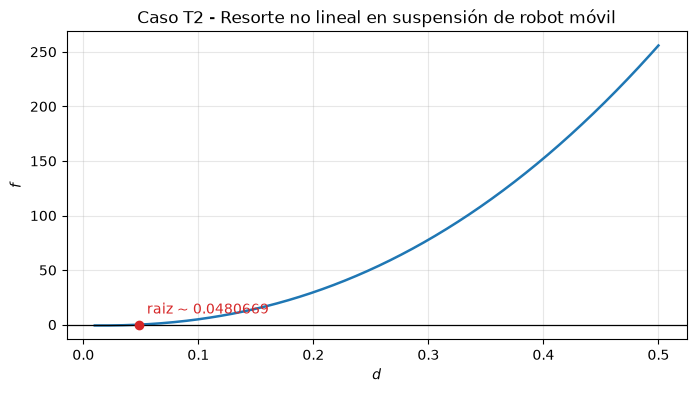

In [ ]:
graficar_caso()          # tu caso (sin la raíz marcada)
graficar_caso('otro')    # el caso desconocido


In [9]:
#@title Pregunta 6 · El otro caso (desconocido)
pregunta(6)


#### Pregunta 6 · Caso de estudio T6

**Valor:** $\frac{22}{100}$ puntos

**Tensión en cable de catenaria.** Incógnita: $T_A$ (en N).

<IPython.core.display.Math object>

| Parámetro | Valor nominal |
|---|---|
| $w$ | $20.1965$ |  
| $x$ | $9.74868$ |  
| $y$ | $14.7182$ |  
| $y0$ | $0$ |

*Estos coeficientes son **tuyos**: nadie más tiene los mismos números, aunque le toque el mismo caso.*

Intervalo donde aislar la raíz: $[20,\ 5000]$.

Escribe la función `raiz(f, a, b)` que regrese `(raiz, iteraciones)`. **Tú eliges el método numérico** (no se te dice cuál): puede ser cerrado (usa $[a,b]$ como intervalo), abierto (usa $a$ y $b$ como arranque, o una derivada numérica), etc. Se probará contra muchos valores de los parámetros.

In [10]:
#@title ✍️ (Opcional) Método para el OTRO caso: raiz_otro(f, a, b)
#  Si quieres usar un MÉTODO DISTINTO para el caso desconocido, define aquí
#  `raiz_otro(f, a, b)` con el mismo contrato: devuelve (raiz, iteraciones).
#  Si NO la defines (deja este bloque comentado), se usa tu `raiz` de arriba
#  para los dos casos.
#
# def raiz_otro(f, a, b):
#     # ... tu método para el otro caso ...
#     return 0.0, 0


In [ ]:
# Ya con `raiz_otro` definida, revisa el otro caso:
# mi_caso('otro')
# graficar_caso('otro')


## 3 · Convergencia y resultado

In [11]:
#@title Pregunta 7
pregunta(7)


#### Pregunta 7

**Valor:** $\frac{8}{100}$ puntos

¿Cuándo puede **divergir** Newton-Raphson?

a) Cuando la derivada es ~0 en el arranque o hay un mal punto inicial.  
b) Nunca: siempre converge.  
c) Siempre que la función sea no lineal.  
d) Cuando la raíz es racional.

RadioButtons(options=(('a', 0), ('b', 1), ('c', 2), ('d', 3)), value=None)

In [12]:
#@title Pregunta 8 · La raíz de tu caso
pregunta(8)


#### Pregunta 8 · La raíz de tu caso

**Valor:** $\frac{8}{100}$ puntos

Con tu método, ¿a qué raíz llegaste para **tu** caso (el de la pregunta anterior)? Escribe el número con 4 decimales.

FloatText(value=0.0, description='Raíz:')

---

## Calificar y enviar

Esta celda califica tu examen y, **si tu calificación es ≥ 80 %, envía tus respuestas automáticamente**. Cada ejecución cuenta como un intento y queda registrada en el servidor (no se reinicia borrando archivos locales), así que revisa tus respuestas antes de calificar.


In [13]:
#@title 📝 Calificar (envía automáticamente si ≥ 80 %)
calificar()


**Intento 1.** Te quedan 2 intento(s) antes de que cambien las preguntas teóricas.

## 📝 Calificación

**0.0 / 100** puntos

❌ Aún estás por debajo del **80 %** (80 puntos). Corrige y vuelve a ejecutar esta celda.